# 01 – Hane (UCI IHEPC): veriden sonuca, donmuş final sonuçların yeniden üretimi

Bu notebook projenin **hane** veri setindeki akışı baştan sona gösterir: veri → EDA özeti → bölme → modeller → kayıtlı ağırlıklarla tahmin → sonuç tabloları ve figürler → anomali.

**Kurallar (CLAUDE.md):**
- Yalnız **donmuş** sonuçlar. Hesaplar yalnız **val** üzerinde yapılır; **test kümesinde hiçbir hesap yapılmaz**. Test sonuçları yalnız kayıtlı final tablolardan *okunur*.
- Repodaki fonksiyonlar çağrılır; yeni hesaplama yöntemi yazılmaz. CLI `main()` fonksiyonları çağrılmaz (onlar `results/`'a yazar).
- `results/` ve `experiments.csv` değiştirilmez: ilk hücrede dosyaların anlık görüntüsü alınır, son hücrede değişmediği doğrulanır. Figürler geçici bir klasöre çizilir.
- **Eğitim yapan hücreler varsayılan olarak çalışmaz** (`RUN_TRAINING = False`). Derin modeller kayıtlı checkpoint'lerden yüklenir; XGBoost'un val tahmini kayıtlı dosyadan okunur. `REFIT_FAST = True` yalnız saniyeler süren, seed'i sabit iki fit'i açar: Ridge (kapalı çözüm) ve Isolation Forest (anomali A1). Kapatılırsa Ridge kayıtlı tahminden okunur ve anomali yeniden üretimi atlanır.

In [1]:
# Kurulum: proje kökü, bayraklar, cihaz. Bu hücre hiçbir dosyaya yazmaz.
import os, sys, tempfile, warnings
from copy import deepcopy
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from src.core.config import PROJECT_ROOT, load_config
from src.core.results_io import resolve_path
from src.core.seed import get_device, set_seed

# --- Bayraklar ---------------------------------------------------------------
RUN_TRAINING = False   # True: sinir ağı eğitimi / Optuna / XGBoost yeniden fit (uzun; results/ ve experiments.csv'ye YAZAR)
REFIT_FAST = True      # True: Ridge (kapalı çözüm) ve Isolation Forest yalnız train ile yeniden fit (saniyeler, seed sabit)
XGB_THREADS = 12       # XGBoost çıktısı iş parçacığı sayısına bağlı; kayıtlı sonuçlar 12 ile üretildi (CLAUDE.md)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
device = get_device("cuda")
FIG_DIR = Path(tempfile.mkdtemp(prefix="notebook_figures_"))   # figürler results/ DIŞINA (geçici klasör)
print("Proje kökü:", PROJECT_ROOT, "| cihaz:", device, "| geçici figür klasörü:", FIG_DIR)


Proje kökü: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini | cihaz: cuda | geçici figür klasörü: C:\Users\sseyd\AppData\Local\Temp\notebook_figures_zumecfhl


In [2]:
# results/ altındaki her dosyanın (boyut, değişiklik zamanı) anlık görüntüsü: en sonda değişmediği doğrulanır.
def results_snapshot():
    """{göreli yol: (boyut, mtime_ns)} — results/ altındaki bütün dosyalar."""
    base = PROJECT_ROOT / "results"
    return {p.relative_to(base).as_posix(): (p.stat().st_size, p.stat().st_mtime_ns)
            for p in base.rglob("*") if p.is_file()}

SNAPSHOT_START = results_snapshot()
print(len(SNAPSHOT_START), "dosya kaydedildi")


529 dosya kaydedildi


In [3]:
# Karşılaştırma yardımcısı: yeniden üretilen tablo ile kayıtlı tablo, anahtar sütunlarda birleştirilip sayısal
# sütunlarda en büyük mutlak fark hesaplanır. Tolerans 1e-6 (float32 yuvarlaması bunun çok altında).
TOLERANCE = 1e-6
CHECKS = []

def compare_tables(name, new, saved, keys, columns, tol=TOLERANCE):
    """Satır sayıları ve sütun başına en büyük |fark|; sonucu CHECKS listesine ekler."""
    merged = new.merge(saved, on=keys, suffixes=("", "_kayitli"), how="outer", indicator=True)
    both = merged["_merge"] == "both"
    worst = max(float((merged.loc[both, c] - merged.loc[both, c + "_kayitli"]).abs().max()) for c in columns)
    ok = bool(both.all()) and worst <= tol
    CHECKS.append({"kontrol": name, "yeni_satir": len(new), "kayitli_satir": len(saved),
                   "eslesen": int(both.sum()), "max_abs_fark": worst, "tamam": ok})
    return ok


## 1. Veri

İşlenmiş saatlik veri (`data/processed/hourly.parquet`): `python -m src.datasets.household.preprocess` ile dakikalık ham UCI verisinden üretilmiştir (saatlik ortalama kW; eksik saatler doldurulmuş ve `is_imputed` ile işaretlenmiştir). Burada yalnız okunur.

In [4]:
config = load_config()
df = pd.read_parquet(resolve_path(PROJECT_ROOT, config["paths"]["processed_file"]))
target = config["preprocess"]["target"]
print("Satır:", len(df), "| aralık:", df.index.min(), "→", df.index.max(), "| hedef:", target)
print("Doldurulmuş saat oranı:", round(float(df["is_imputed"].mean()), 4) if "is_imputed" in df else "—")
display(df.head())

Satır: 34589 | aralık: 2006-12-16 17:00:00 → 2010-11-26 21:00:00 | hedef: Global_active_power
Doldurulmuş saat oranı: 0.0125


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,other_energy,is_imputed,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,is_weekend,is_holiday
datetime,,,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,3596.888889,0,-0.965926,-2.588190e-01,-0.974928,-0.222521,-0.5,0.866025,1,0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,2217.200000,0,-1.000000,-1.836970e-16,-0.974928,-0.222521,-0.5,0.866025,1,0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,2313.233333,0,-0.965926,2.588190e-01,-0.974928,-0.222521,-0.5,0.866025,1,0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,2261.566667,0,-0.866025,5.000000e-01,-0.974928,-0.222521,-0.5,0.866025,1,0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1998.466667,0,-0.707107,7.071068e-01,-0.974928,-0.222521,-0.5,0.866025,1,0


## 2. EDA özeti

EDA `notebooks/01_eda.ipynb`'de yapıldı; figürleri `results/figures/eda_*.png` altında. Burada yalnız gösterilir (yeniden hesaplanmaz): günlük profil, saat × gün ısı haritası, aylık eğilim ve otokorelasyon.

eda_daily_profile.png


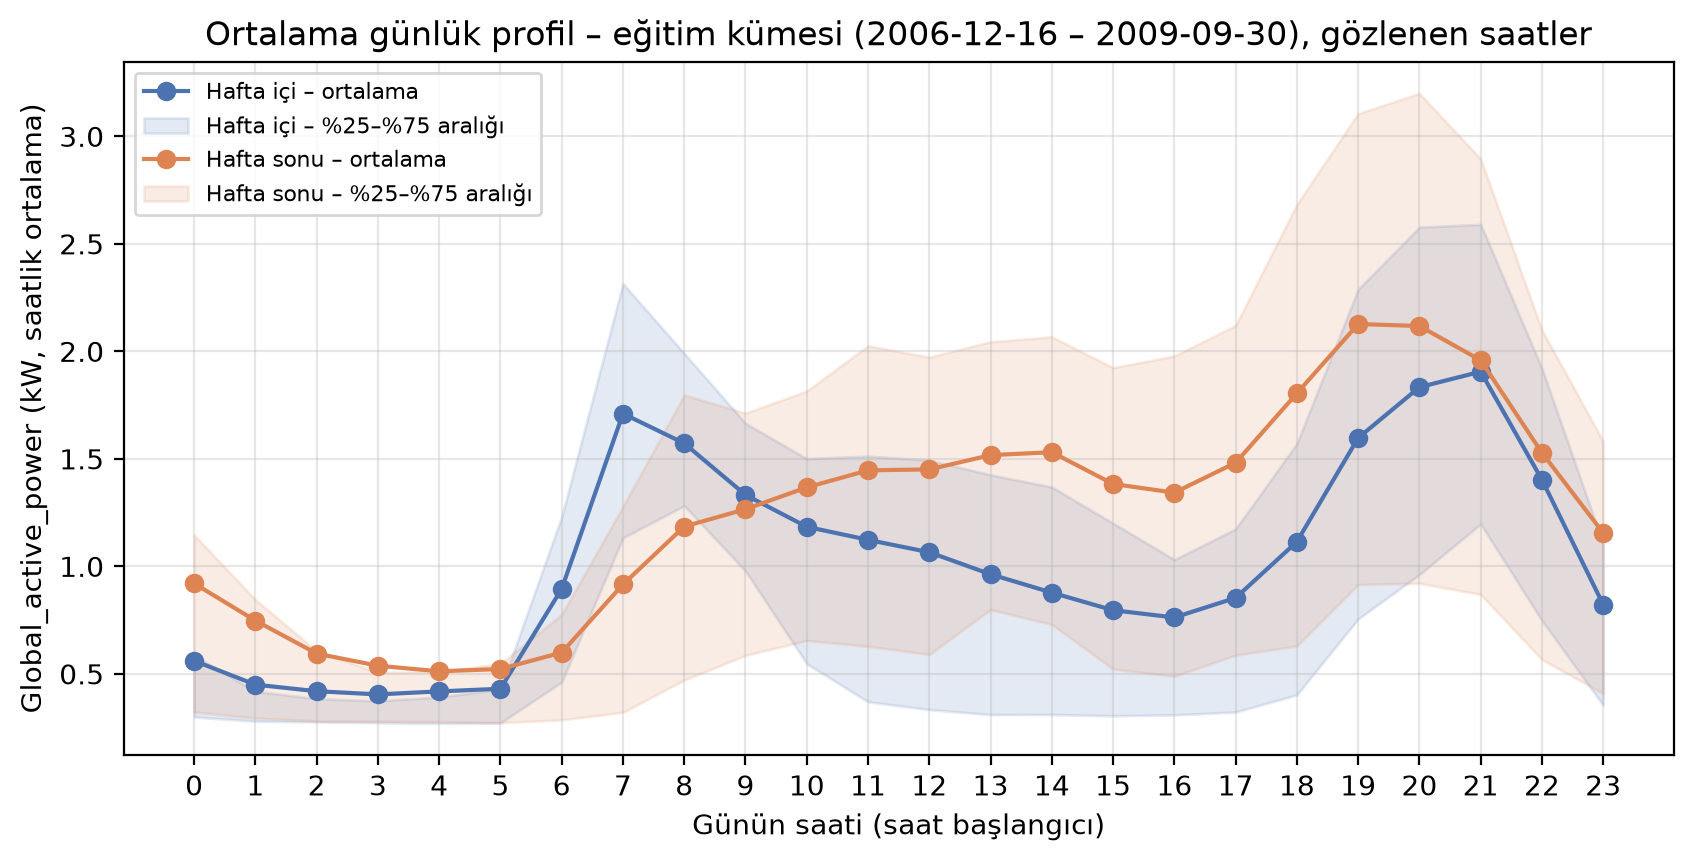

eda_heatmap_hour_dow.png


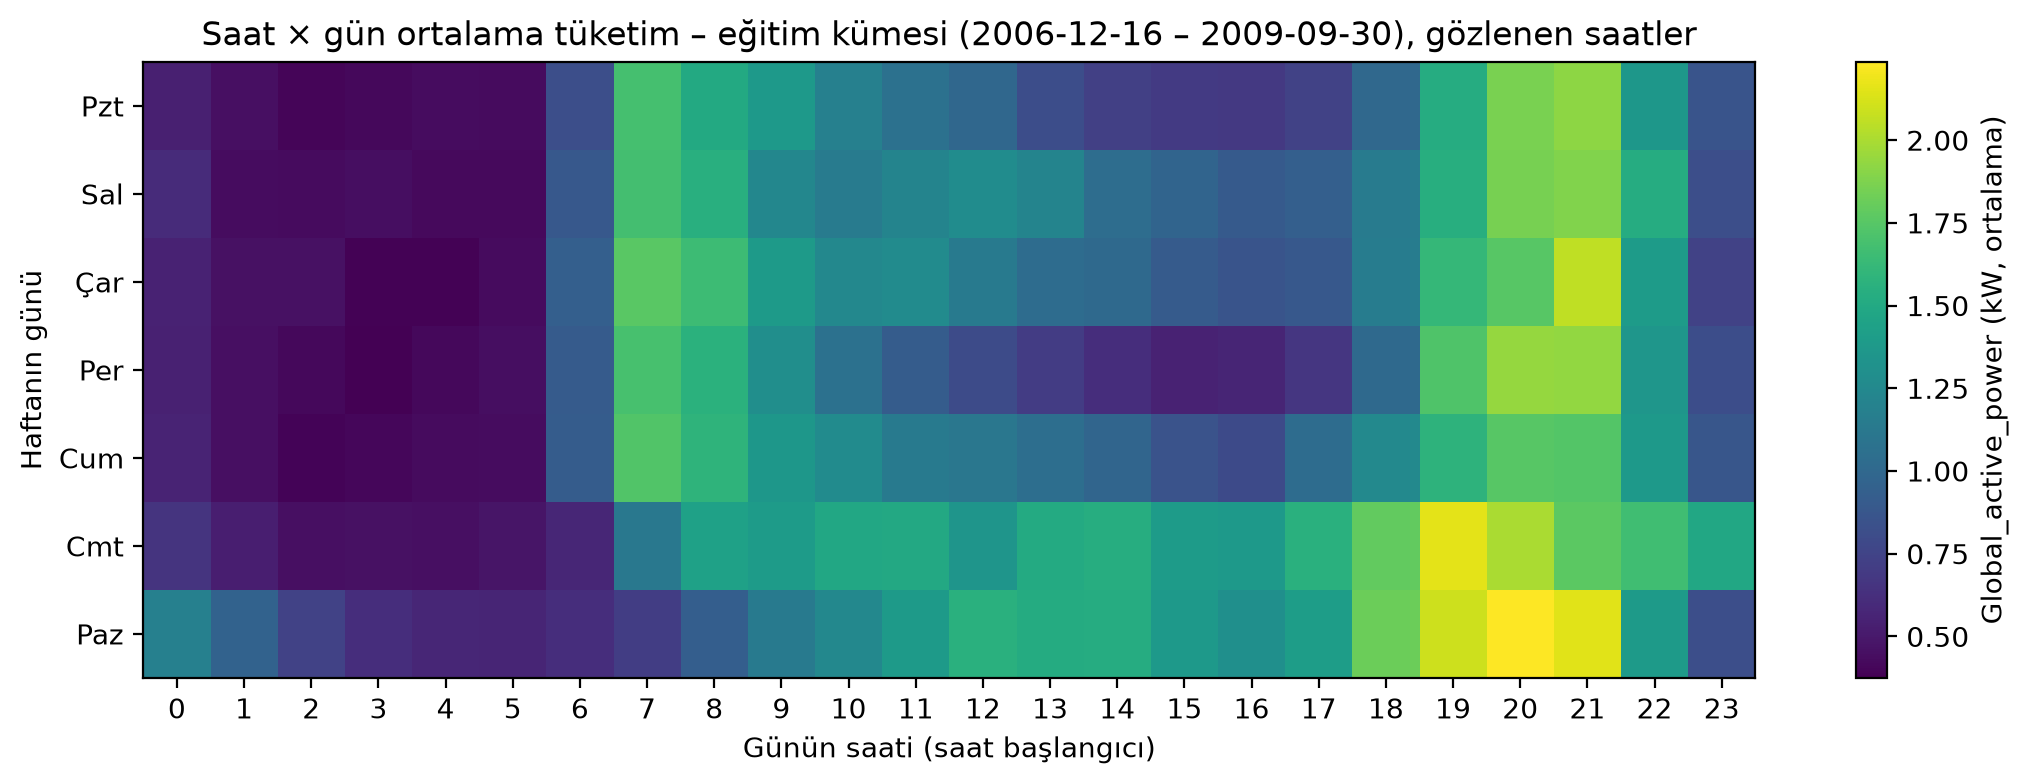

eda_monthly_trend.png


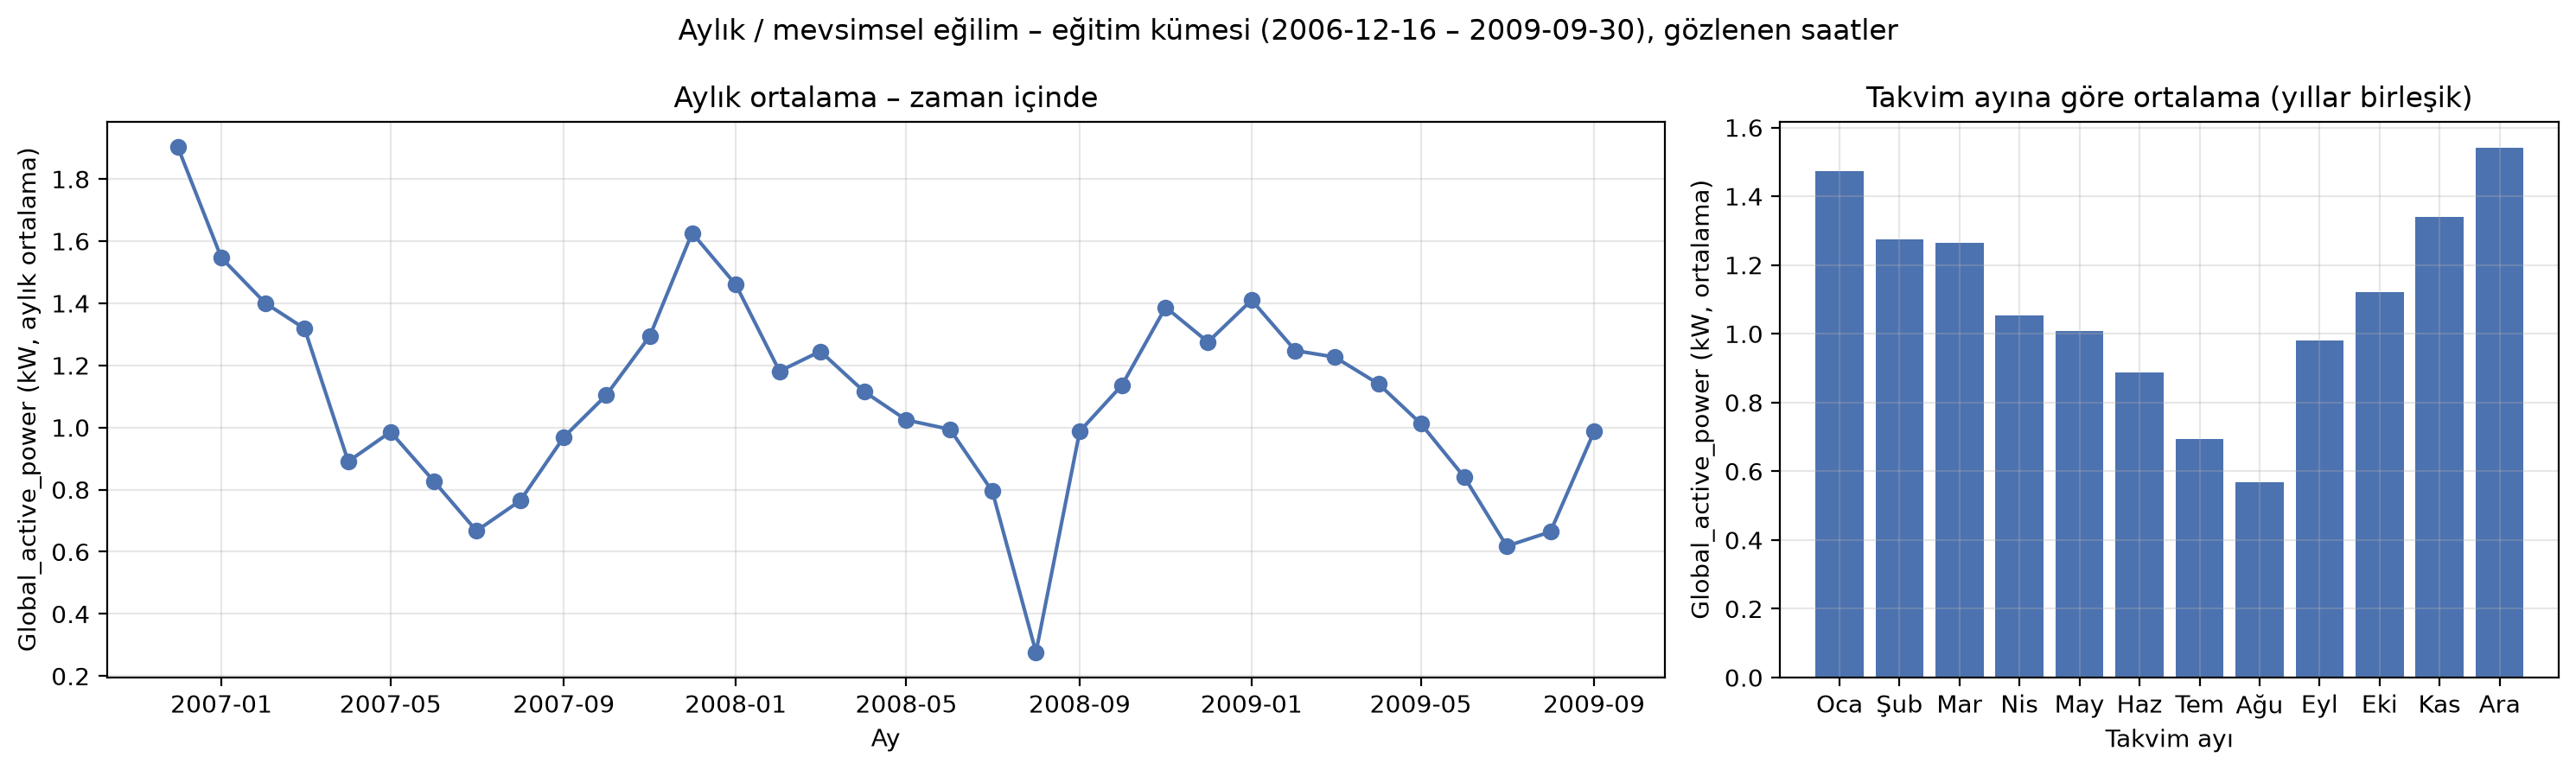

eda_acf.png


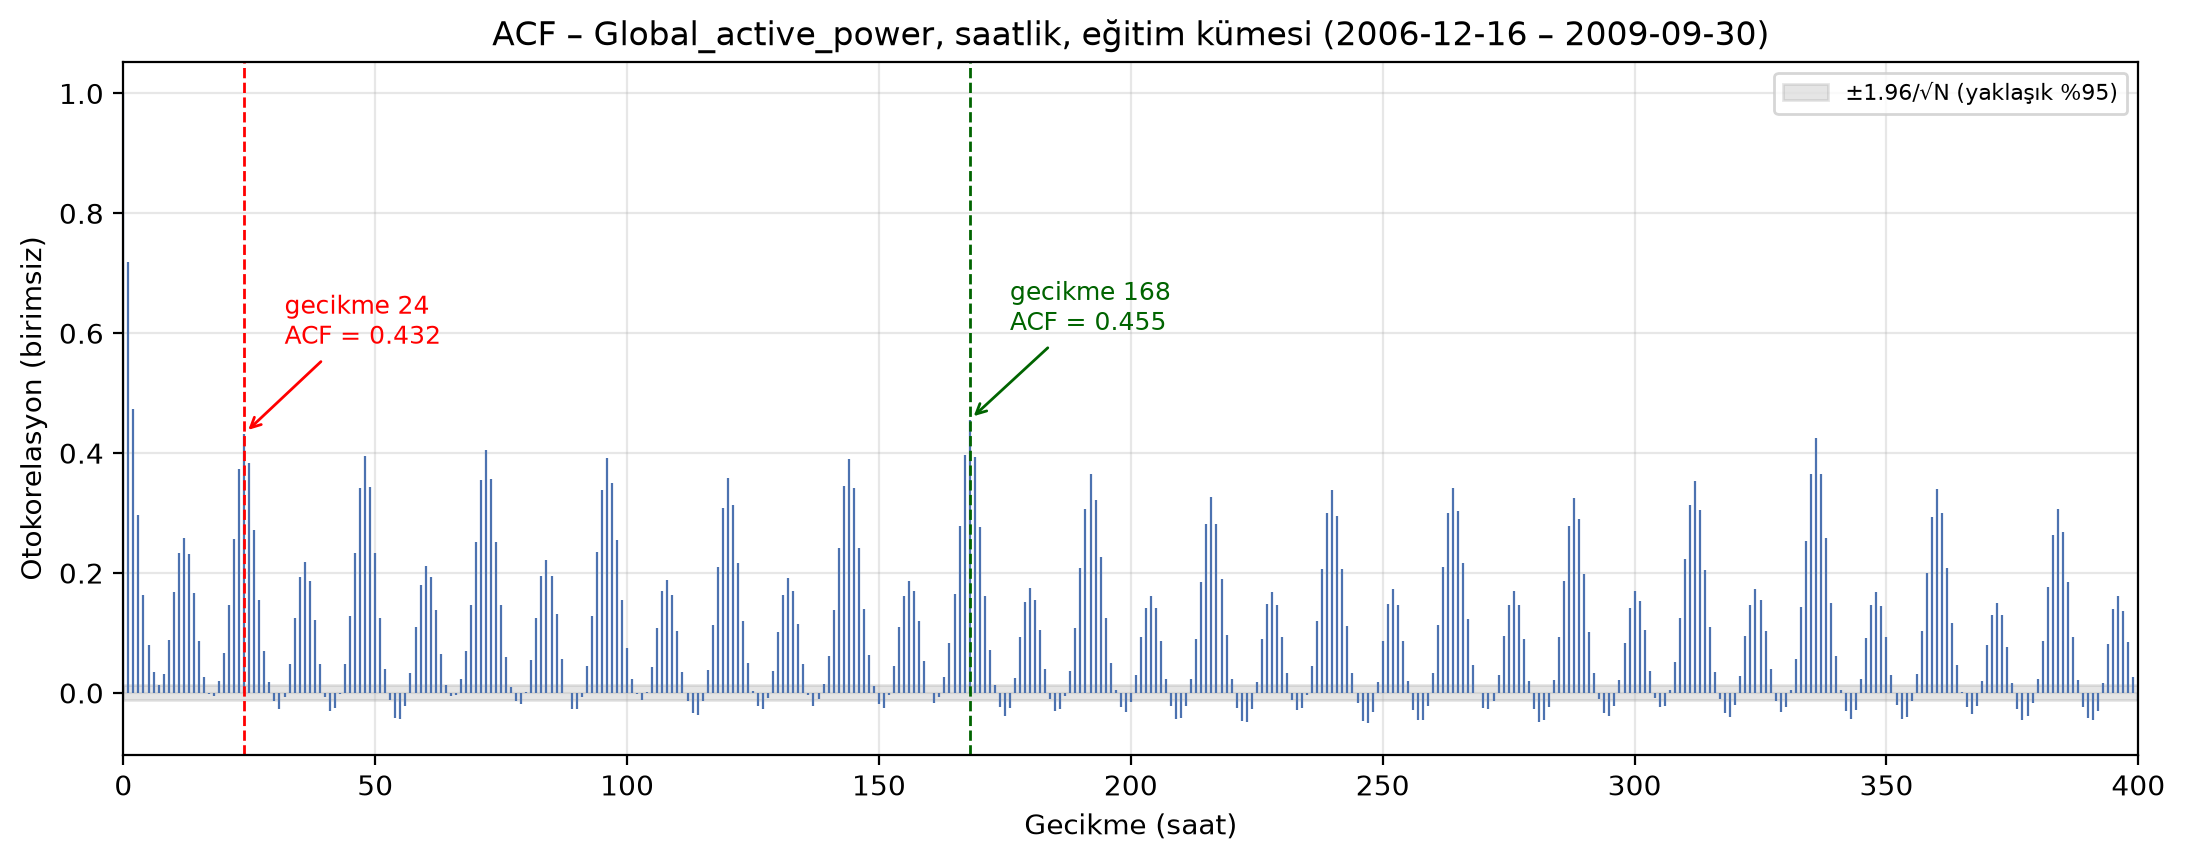

In [5]:
for name in ["eda_daily_profile.png", "eda_heatmap_hour_dow.png", "eda_monthly_trend.png", "eda_acf.png"]:
    path = PROJECT_ROOT / "results" / "figures" / name
    if path.is_file():
        print(name); display(Image(filename=str(path), width=700))

## 3. Bölme (kronolojik)

Bölme tarihleri `configs/config.yaml`'dadır; rastgele bölme yoktur. Test aralığı yalnız bilgi için gösterilir, kullanılmaz.

In [6]:
from src.core.split import chronological_split
from src.pipelines.anomaly_protocol import protocol_splits

parts = protocol_splits(df, config)       # train, val, test + anomali protokolü için val_dev / val_hold
display(pd.DataFrame([{"parça": k, "başlangıç": v.index.min(), "bitiş": v.index.max(), "saat": len(v)}
                      for k, v in parts.items()]))

,parça,başlangıç,bitiş,saat
0,train,2006-12-16 17:00:00,2009-09-30 23:00:00,24463
1,val,2009-10-01 00:00:00,2010-03-31 23:00:00,4368
2,test,2010-04-01 00:00:00,2010-11-26 21:00:00,5758
3,val_dev,2009-10-01 00:00:00,2009-12-31 23:00:00,2208
4,val_hold,2010-01-01 00:00:00,2010-03-31 23:00:00,2160


## 4. Modeller

Final kadro (`src/pipelines/evaluate_forecast.py::ROSTER`): naif referanslar F0–F2, Ridge, MLP, LSTM (F5-opt, 3 seed), GRU, Seq2Seq-LSTM (F10-opt, 3 seed), CNN-LSTM, XGBoost ve final topluluk **F13-ens = 0,8 · F10-opt + 0,2 · F5-opt**. Ayarlar checkpoint'lerde ve `configs/optuna_*_best.yaml`'dadır.

Eğitim komutları aşağıdaki hücrede yalnız `RUN_TRAINING = True` ise çalışır (uzun sürer, `results/` ve `experiments.csv`'ye yazar; donmuş sonuçları değiştirmemek için **varsayılan kapalı**).

In [7]:
from src.pipelines import evaluate_forecast as ef

display(pd.DataFrame([{"exp_id": k, "aile": v[0], "model": v[1], "öznitelik seti": v[2], "lookback": v[3]}
                      for k, v in ef.ROSTER.items()]))
print("Topluluk:", ef.ENSEMBLE, "ağırlıklar (F10, F5):", ef.ENSEMBLE_WEIGHTS)

,exp_id,aile,model,öznitelik seti,lookback
0,F3-cal,ridge,Ridge,B,168.0
1,F4-torch-128x64-fut,torch,MLP,B,NaN
2,F5-opt,torch,LSTM,B,NaN
3,F5-opt-s7,torch,LSTM,B,NaN
4,F5-opt-s2026,torch,LSTM,B,NaN
5,F6-C,torch,GRU,C,NaN
6,F10-opt,torch,Seq2Seq-LSTM,B,NaN
7,F10-opt-s7,torch,Seq2Seq-LSTM,B,NaN
8,F10-opt-s2026,torch,Seq2Seq-LSTM,B,NaN
9,F11-L48,torch,CNN-LSTM,B,NaN


Topluluk: {'F13-ens': ('F10-opt', 'F5-opt'), 'F13-ens-s7': ('F10-opt-s7', 'F5-opt-s7'), 'F13-ens-s2026': ('F10-opt-s2026', 'F5-opt-s2026')} ağırlıklar (F10, F5): (0.8, 0.2)


In [8]:
# EĞİTİM (varsayılan kapalı). Örnek komutlar; tam liste README §5.
TRAINING_COMMANDS = [
    "python -m src.pipelines.train_forecast --model seq2seq --exp F10-opt --config configs/optuna_seq2seq_best.yaml",
    "python -m src.pipelines.train_forecast --model lstm --exp F5-opt --config configs/optuna_lstm_best.yaml",
    "python -m src.pipelines.train_oof --help",
    "python -m src.pipelines.train_autoencoder --exp A2",
]
if RUN_TRAINING:
    import subprocess
    for command in TRAINING_COMMANDS:
        subprocess.run(command.split(), check=True, cwd=PROJECT_ROOT)
else:
    print("RUN_TRAINING = False: eğitim atlandı; kayıtlı ağırlıklar kullanılacak.")

RUN_TRAINING = False: eğitim atlandı; kayıtlı ağırlıklar kullanılacak.


## 5. Kayıtlı ağırlıklarla tahmin (val)

`all_predictions(df, config, "val", ...)` derin modelleri `models/*_best.pt` checkpoint'lerinden yükler ve val pencerelerinde 24 saatlik tahmin üretir. XGBoost (kayıtlı ağırlığı yok; val ile erken durdurmalı yeniden fit gerekir) `RUN_TRAINING = False` iken kayıtlı val tahmininden (`results/predictions/*_val.npz`) okunur. Ridge `REFIT_FAST = True` iken kapalı çözümle yeniden fit edilir.

In [9]:
run_config = deepcopy(config)
run_config["forecast"]["xgboost"]["n_jobs"] = XGB_THREADS
predictions_dir = resolve_path(PROJECT_ROOT, config["paths"]["predictions_dir"])

def from_saved(exp_id):
    """Kayıtlı val tahmini: (y_true [N,24], y_pred [N,24], ilk hedef saatleri [N])."""
    data = np.load(predictions_dir / f"{exp_id}_val.npz")
    return data["y_true"], data["y_pred"], pd.to_datetime(data["target_times"], unit="ns")

skip = {"xgboost"} if not RUN_TRAINING else set()
if not REFIT_FAST:
    skip.add("ridge")
roster = {k: v for k, v in ef.ROSTER.items() if v[0] not in skip}
results = ef.all_predictions(df, run_config, "val", device, roster=roster)
for exp_id in set(ef.ROSTER) - set(roster):
    results[exp_id] = from_saved(exp_id)
print("Kayıtlı dosyadan okunan:", sorted(set(ef.ROSTER) - set(roster)))

F3-cal: 4213 pencere


F4-torch-128x64-fut: 4213 pencere


F5-opt: 4213 pencere


F5-opt-s7: 4213 pencere


F5-opt-s2026: 4213 pencere


F6-C: 4213 pencere


F10-opt: 4213 pencere


F10-opt-s7: 4213 pencere


F10-opt-s2026: 4213 pencere


F11-L48: 4213 pencere
Kayıtlı dosyadan okunan: ['F12-L336']


In [10]:
# Dizi düzeyinde kontrol: yeniden üretilen val tahminleri kayıtlı val tahminleriyle aynı mı?
check = ef.verify_against_saved_val(results, config)
display(check)
worst = float(check[["max_abs_diff_true", "max_abs_diff_pred_kw"]].to_numpy().max())
CHECKS.append({"kontrol": "hane val tahminleri = kayıtlı .npz (kW)", "yeni_satir": len(check),
               "kayitli_satir": len(check), "eslesen": int(check["same_windows"].sum()),
               "max_abs_fark": worst, "tamam": bool(check["same_windows"].all()) and worst <= TOLERANCE})

,exp_id,same_windows,max_abs_diff_true,max_abs_diff_pred_kw
0,F0,True,2.281189e-07,2.281189e-07
1,F1,True,2.281189e-07,2.281189e-07
2,F2,True,2.281189e-07,2.281189e-07
3,F3-cal,True,0.000000e+00,0.000000e+00
4,F4-torch-128x64-fut,True,0.000000e+00,0.000000e+00
5,F5-opt,True,0.000000e+00,0.000000e+00
6,F5-opt-s7,True,0.000000e+00,0.000000e+00
7,F5-opt-s2026,True,0.000000e+00,0.000000e+00
8,F6-C,True,0.000000e+00,0.000000e+00
9,F10-opt,True,0.000000e+00,0.000000e+00


## 6. Sonuç tabloları ve figürler (val)

Üç seviyede rapor (`src/pipelines/forecast_levels.py::level_metrics`): (a) h = 1, (b) 24 saat ortalaması (ana metrik), (c) günlük toplam (kWh). Kayıtlı karşılığı `results/tables/forecast_levels_val.csv` ve `_per_seed.csv`.

In [11]:
from src.pipelines.forecast_levels import MODELS, level_metrics

rows = []
for label, exp_ids in MODELS.items():
    for exp_id in exp_ids:
        y_true, y_pred, times = results[exp_id]
        for level, metrics in level_metrics(y_true, y_pred, pd.DatetimeIndex(times),
                                            config["evaluation"]["mape_min_y"]).items():
            rows.append({"model": label, "exp_id": exp_id, "level": level, **metrics})
levels_per_seed = pd.DataFrame(rows)
metric_names = ["MAE", "RMSE", "MAPE*", "sMAPE", "R2"]
levels = levels_per_seed.groupby(["model", "level"], sort=False).agg(
    n_seeds=("exp_id", "count"), n=("n", "first"),
    **{f"{m}_mean": (m, "mean") for m in metric_names}, **{f"{m}_std": (m, "std") for m in metric_names}).reset_index()
display(levels.round(4))

tables_dir = resolve_path(PROJECT_ROOT, config["paths"]["tables_dir"])
compare_tables("hane forecast_levels_val_per_seed.csv", levels_per_seed,
               pd.read_csv(tables_dir / "forecast_levels_val_per_seed.csv"), ["exp_id", "level"], metric_names)
compare_tables("hane forecast_levels_val.csv", levels, pd.read_csv(tables_dir / "forecast_levels_val.csv"),
               ["model", "level"], [f"{m}_mean" for m in metric_names])

,model,level,n_seeds,n,MAE_mean,RMSE_mean,MAPE*_mean,sMAPE_mean,R2_mean,MAE_std,RMSE_std,MAPE*_std,sMAPE_std,R2_std
0,F13-ens,a_h1,3,4213,0.3822,0.5594,36.6625,31.5867,0.6248,0.0072,0.0053,1.4184,0.5495,0.0071
1,F13-ens,b_24h,3,4213,0.4625,0.6785,46.6767,37.4377,0.4470,0.0027,0.0028,0.3976,0.1861,0.0046
2,F13-ens,c_daily,3,177,5.0012,6.5996,16.7745,17.1035,0.1680,0.1663,0.3084,0.4939,0.8031,0.0785
3,F10-opt,a_h1,3,4213,0.3870,0.5668,36.7687,31.9151,0.6148,0.0091,0.0069,1.5387,0.7366,0.0093
4,F10-opt,b_24h,3,4213,0.4688,0.6907,46.6602,37.7674,0.4270,0.0060,0.0072,0.7354,0.5131,0.0119
5,F10-opt,c_daily,3,177,5.1063,6.7552,17.2141,17.7108,0.1280,0.1701,0.3546,0.5910,1.0106,0.0927
6,F5-opt,a_h1,3,4213,0.3885,0.5595,39.6357,33.2600,0.6247,0.0043,0.0065,0.4935,0.7040,0.0087
7,F5-opt,b_24h,3,4213,0.4810,0.6822,52.1326,40.4781,0.4411,0.0016,0.0006,1.1035,0.3328,0.0010
8,F5-opt,c_daily,3,177,4.9362,6.5193,16.5369,16.5244,0.1891,0.0893,0.1417,0.1511,0.1553,0.0350
9,F2 (Seasonal Naive 168),a_h1,1,4213,0.6216,0.9051,65.1715,48.3131,0.0180,NaN,NaN,NaN,NaN,NaN


True

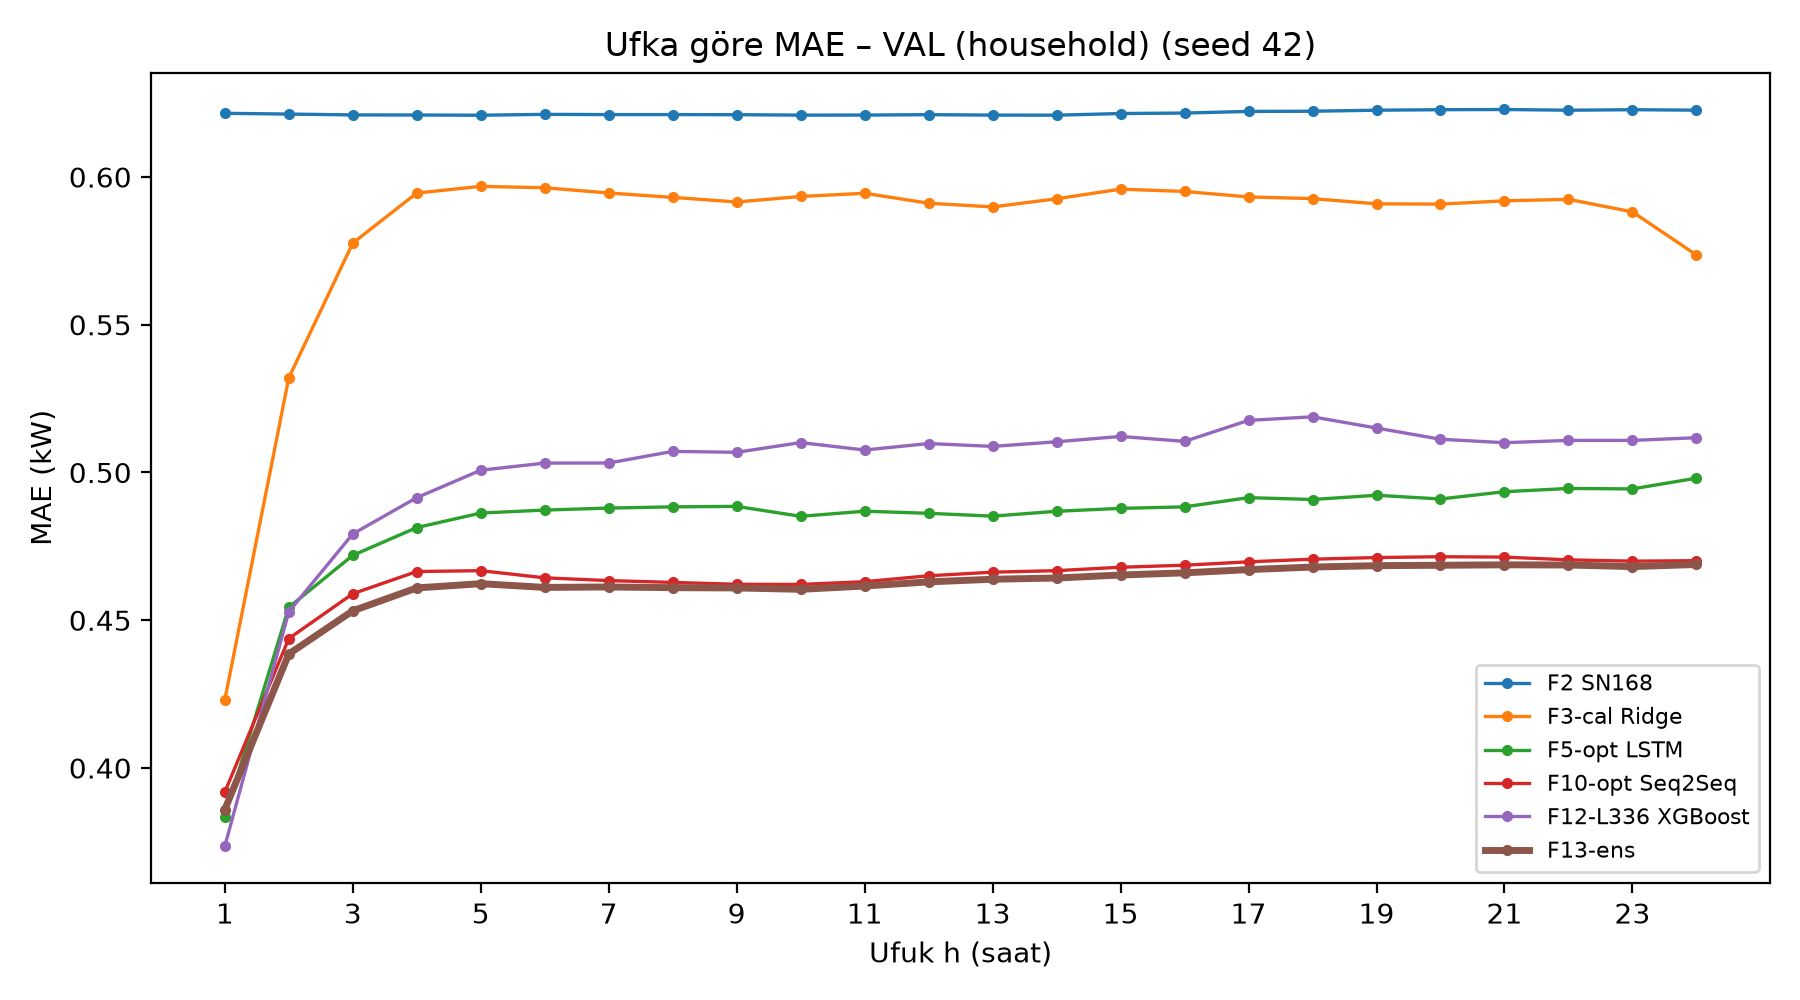

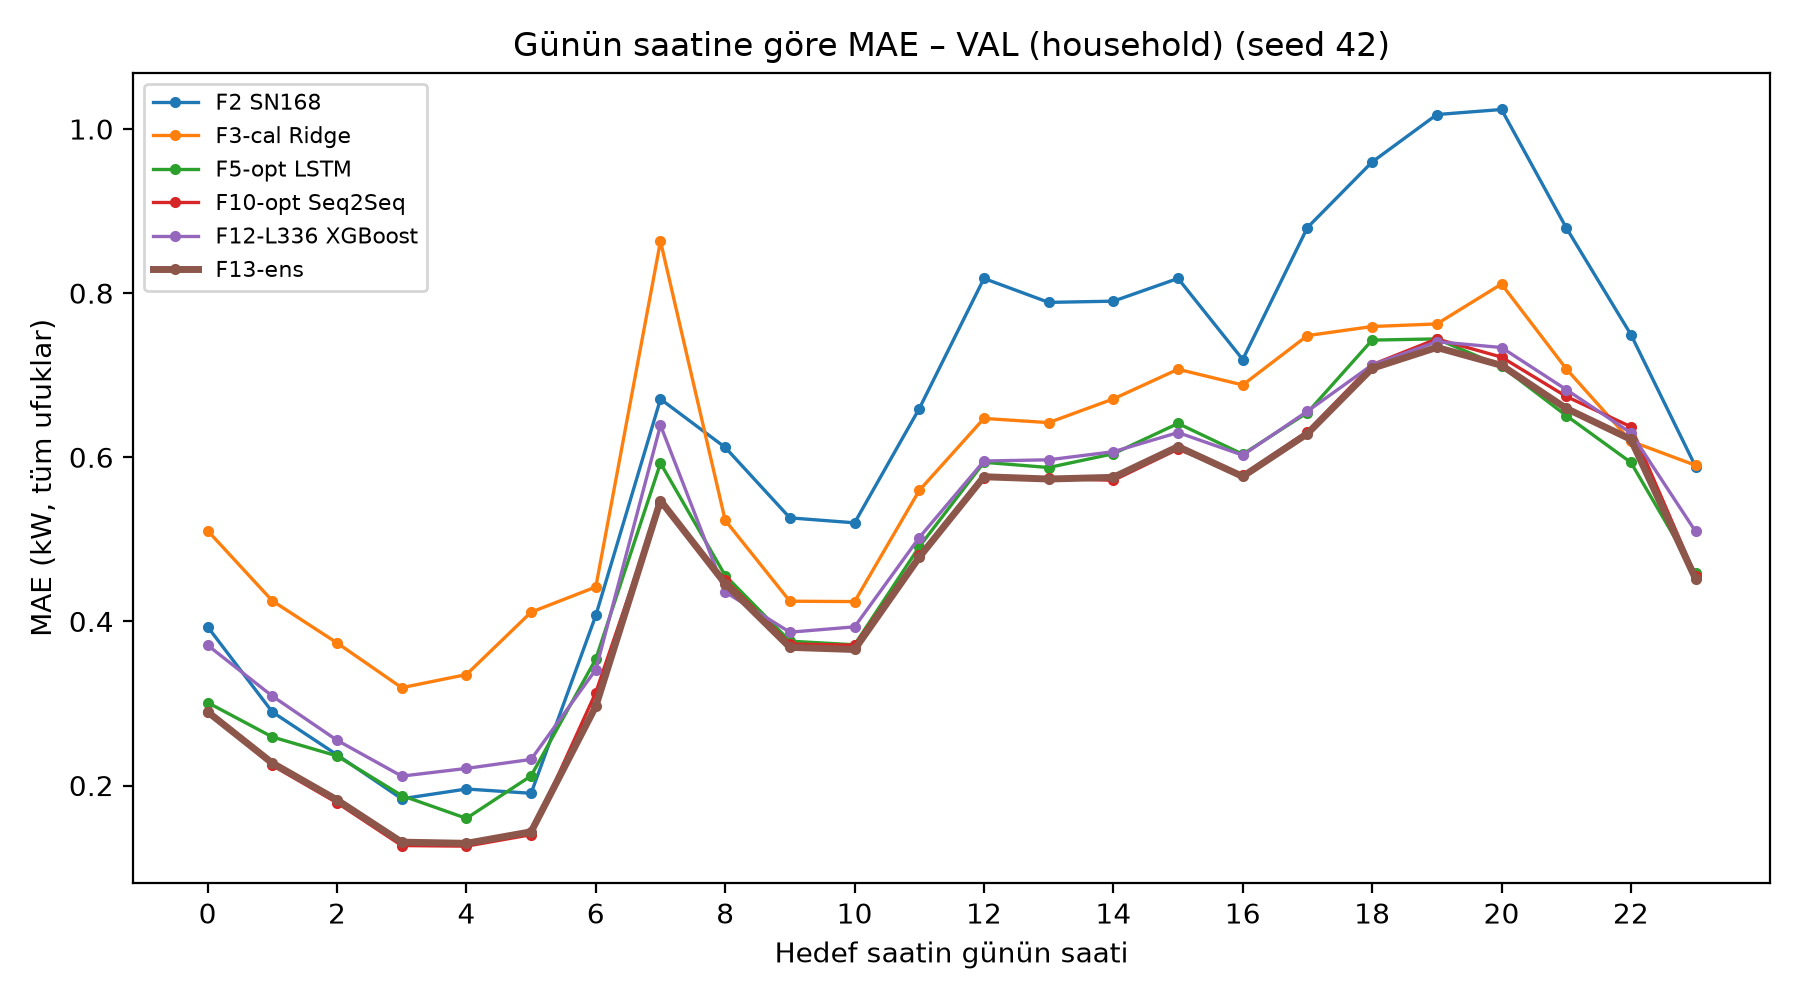

In [12]:
# Figürler (val): ufka ve günün saatine göre MAE — geçici klasöre çizilir, burada gösterilir.
ef.save_error_figures(results, FIG_DIR, "val")
for name in ["F_final_val_mae_by_horizon.png", "F_final_val_mae_by_hour.png"]:
    display(Image(filename=str(FIG_DIR / name), width=750))

In [13]:
# Donmuş final tablo (val ve test yan yana) — YALNIZ OKUNUR; test burada hesaplanmaz.
final_forecast = pd.read_csv(tables_dir / "final_forecast_val_vs_test.csv")
display(final_forecast.round(4))

,group,n_seeds,val_MAE_mean,val_MAE_std,val_RMSE_mean,val_RMSE_std,val_R2_mean,val_R2_std,test_MAE_mean,test_MAE_std,test_RMSE_mean,test_RMSE_std,test_R2_mean,test_R2_std,val_vs_SN168_pct,test_vs_SN168_pct
0,F0 Persistence,1,0.9598,NaN,1.2537,NaN,-0.8880,NaN,0.6916,NaN,0.9423,NaN,-0.7488,NaN,-54.4073,-25.9932
1,F1 Seasonal Naive 24,1,0.6913,NaN,0.9898,NaN,-0.1767,NaN,0.5118,NaN,0.7597,NaN,-0.1366,NaN,-11.2035,6.7580
2,F2 Seasonal Naive 168,1,0.6216,NaN,0.9053,NaN,0.0156,NaN,0.5489,NaN,0.7948,NaN,-0.2442,NaN,0.0000,0.0000
3,F3-cal Ridge,1,0.5819,NaN,0.7608,NaN,0.3048,NaN,0.4666,NaN,0.6120,NaN,0.2622,NaN,6.3863,15.0046
4,F4 MLP (fut),1,0.5019,NaN,0.6859,NaN,0.4349,NaN,0.4316,NaN,0.5840,NaN,0.3283,NaN,19.2542,21.3710
5,F5-opt LSTM,3,0.4810,0.0016,0.6822,0.0006,0.4411,0.0010,0.4128,0.0047,0.5806,0.0020,0.3362,0.0046,22.6211,24.7943
6,F6-C GRU,1,0.4878,NaN,0.6818,NaN,0.4416,NaN,0.4168,NaN,0.5812,NaN,0.3347,NaN,21.5263,24.0638
7,F10-opt Seq2Seq,3,0.4688,0.0060,0.6907,0.0072,0.4270,0.0119,0.4136,0.0070,0.6117,0.0120,0.2628,0.0290,24.5911,24.6570
8,F11-L48 CNN-LSTM,1,0.4838,NaN,0.6818,NaN,0.4417,NaN,0.4257,NaN,0.5816,NaN,0.3338,NaN,22.1706,22.4467
9,F12-L336 XGBoost,1,0.4998,NaN,0.6806,NaN,0.4435,NaN,0.4160,NaN,0.5683,NaN,0.3639,NaN,19.6048,24.2204


## 7. Anomali (val)

Final protokol (`src/pipelines/anomaly_protocol.py`, `docs/final_test_protokolu.md`): train ile dedektörler hazırlanır (A0 hareketli z-skoru, A1 Isolation Forest, A2 LSTM-AE, A3 tahmin artığı — A3'ün tahmin modelleri kayıtlı ağırlıklardır, std'si OOF artıklarından). Val'in ilk parçasında (**val_dev**, ana senaryo, 10 enjekte kopya) her yöntem için yumuşatma penceresi ve olay-F1 eşiği seçilir; aynı ayarlar **val_hold**'a ve zor senaryoya aynen uygulanır. Final yöntem: **A3-s2s-norm**.

Bu bölüm `REFIT_FAST = True` gerektirir (Isolation Forest train'e yeniden fit edilir; saniyeler).

In [14]:
from src.core.inject_anomalies import train_sigma_table
from src.pipelines import anomaly_protocol as ap
from src.pipelines.evaluate_anomaly import fit_combination, fit_detectors, summarize

if REFIT_FAST:
    set_seed(config["seed"])
    protocol = config["protocol"]
    fitted = fit_detectors(parts, config, device, std_source=protocol["std_source"])
    sigma_table = train_sigma_table(parts["train"], target)
    combination = fit_combination(parts, config, fitted, device, protocol["combination_components"],
                                  reference_split="val_dev")
    dev_main = ap.score_copies(parts, config, "val_dev", "main", fitted, device, combination, sigma_table)
    all_windows, windows, thresholds = ap.select_on_dev(dev_main, config)
    selection = pd.DataFrame({"method": list(windows), "smooth": list(windows.values()),
                              "threshold": [thresholds[m] for m in windows]})
    display(selection)
    compare_tables("hane anomaly_protocol_selection.csv (pencere, eşik)", selection,
                   pd.read_csv(tables_dir / "anomaly_protocol_selection.csv"), ["method"], ["smooth", "threshold"])
else:
    print("REFIT_FAST = False: anomali yeniden üretimi atlandı.")

,method,smooth,threshold
0,A0,3,6.581299
1,A1,1,0.606507
2,A2,6,0.376771
3,A3-ens-norm,3,3.446891
4,A3-s2s-hmean,3,2.943457
5,A3-s2s-norm,3,3.557971
6,A5-mean-z,3,2.453772


In [15]:
if REFIT_FAST:
    per_seed = [all_windows[all_windows["smooth"] == all_windows["method"].map(windows)]]
    for split, scenario in (("val_dev", "hard"), ("val_hold", "main"), ("val_hold", "hard")):
        outputs = ap.score_copies(parts, config, split, scenario, fitted, device, combination, sigma_table)
        per_seed.append(ap.apply_fixed(outputs, windows, thresholds, split, scenario))
    per_seed = pd.concat(per_seed, ignore_index=True)
    anomaly_summary = summarize(per_seed, ("split", "scenario", "method", "rule", "smooth"))
    display(anomaly_summary[["split", "scenario", "method", "smooth", "event_f1_mean", "event_f1_std",
                             "f1_mean", "pr_auc_mean", "roc_auc_mean"]].round(3))
    metrics = ["event_f1", "f1", "pr_auc", "roc_auc", "event_recall", "threshold"]
    compare_tables("hane anomaly_protocol_val_per_seed.csv", per_seed,
                   pd.read_csv(tables_dir / "anomaly_protocol_val_per_seed.csv"),
                   ["split", "scenario", "seed", "method"], metrics)
    compare_tables("hane anomaly_protocol_val.csv", anomaly_summary, pd.read_csv(tables_dir / "anomaly_protocol_val.csv"),
                   ["split", "scenario", "method"], ["event_f1_mean", "f1_mean", "pr_auc_mean", "roc_auc_mean"])

,split,scenario,method,smooth,event_f1_mean,event_f1_std,f1_mean,pr_auc_mean,roc_auc_mean
0,val_dev,main,A1,1,0.318,0.110,0.316,0.317,0.809
1,val_dev,main,A0,3,0.536,0.206,0.263,0.298,0.848
2,val_dev,main,A3-s2s-norm,3,0.575,0.181,0.319,0.372,0.892
3,val_dev,main,A3-ens-norm,3,0.617,0.196,0.314,0.365,0.891
4,val_dev,main,A3-s2s-hmean,3,0.562,0.127,0.422,0.376,0.913
5,val_dev,main,A5-mean-z,3,0.642,0.114,0.426,0.428,0.903
6,val_dev,main,A2,6,0.364,0.189,0.341,0.339,0.892
7,val_dev,hard,A0,3,0.302,0.200,0.132,0.143,0.740
8,val_dev,hard,A1,1,0.221,0.122,0.098,0.107,0.696
9,val_dev,hard,A2,6,0.141,0.093,0.050,0.071,0.685


In [16]:
# Donmuş final anomali tablosu (val ve test yan yana) — YALNIZ OKUNUR.
display(pd.read_csv(tables_dir / "final_anomaly_val_vs_test.csv").round(3))

,split,scenario,method,smooth,threshold,n_events_mean,event_f1_mean,event_f1_std,event_recall_mean,event_precision_mean,f1_mean,pr_auc_mean,roc_auc_mean
0,val_dev,main,A1,1,0.607,7.5,0.318,0.110,0.282,0.407,0.316,0.317,0.809
1,val_dev,main,A0,3,6.581,7.5,0.536,0.206,0.511,0.613,0.263,0.298,0.848
2,val_dev,main,A3-s2s-norm,3,3.558,7.5,0.575,0.181,0.632,0.569,0.319,0.372,0.892
3,val_dev,main,A3-ens-norm,3,3.447,7.5,0.617,0.196,0.628,0.656,0.314,0.365,0.891
4,val_dev,main,A3-s2s-hmean,3,2.943,7.5,0.562,0.127,0.655,0.523,0.422,0.376,0.913
5,val_dev,main,A5-mean-z,3,2.454,7.5,0.642,0.114,0.671,0.645,0.426,0.428,0.903
6,val_dev,main,A2,6,0.377,7.5,0.364,0.189,0.437,0.337,0.341,0.339,0.892
7,val_dev,hard,A0,3,6.581,6.9,0.302,0.200,0.277,0.383,0.132,0.143,0.740
8,val_dev,hard,A1,1,0.607,6.9,0.221,0.122,0.225,0.241,0.098,0.107,0.696
9,val_dev,hard,A2,6,0.377,6.9,0.141,0.093,0.158,0.135,0.050,0.071,0.685


## 8. Son kontrol: kayıtlı final tablolarla birebir karşılaştırma

Her satır bir kontrol: yeniden üretilen tablo ile kayıtlı tablo anahtar sütunlarda birleştirilir; bütün satırlar eşleşmeli ve sayısal sütunlarda en büyük mutlak fark ≤ 1e-6 olmalı. Son satır `results/` altında hiçbir dosyanın (boyut, değişiklik zamanı) değişmediğini doğrular.

In [17]:
# SON KONTROL: notebook'un ürettiği tablolar kayıtlı final tablolarla birebir mi? results/ değişti mi?
snapshot_end = results_snapshot()
changed = sorted(k for k in set(SNAPSHOT_START) | set(snapshot_end) if SNAPSHOT_START.get(k) != snapshot_end.get(k))
CHECKS.append({"kontrol": "results/ altında değişen dosya yok", "yeni_satir": len(snapshot_end),
               "kayitli_satir": len(SNAPSHOT_START), "eslesen": len(snapshot_end) - len(changed),
               "max_abs_fark": float(len(changed)), "tamam": not changed})
report = pd.DataFrame(CHECKS)
display(report)
if changed:
    print("Değişen dosyalar:", changed[:20])
assert report["tamam"].all(), "Kayıtlı sonuçlarla fark var — yukarıdaki tabloya bakın."
print("Bütün kontroller geçti: notebook çıktıları kayıtlı final tablolarla aynı; results/ değişmedi.")


,kontrol,yeni_satir,kayitli_satir,eslesen,max_abs_fark,tamam
0,hane val tahminleri = kayıtlı .npz (kW),17,17,17,2.281189e-07,True
1,hane forecast_levels_val_per_seed.csv,33,33,33,8.427334e-07,True
2,hane forecast_levels_val.csv,15,15,15,3.525274e-07,True
3,"hane anomaly_protocol_selection.csv (pencere, ...",7,7,7,4.440892e-16,True
4,hane anomaly_protocol_val_per_seed.csv,280,280,280,4.440892e-16,True
5,hane anomaly_protocol_val.csv,28,28,28,1.110223e-16,True
6,results/ altında değişen dosya yok,529,529,529,0.000000e+00,True


Bütün kontroller geçti: notebook çıktıları kayıtlı final tablolarla aynı; results/ değişmedi.
